### 3.1 Understanding the dataset

1. Import the dataset in a notebook environment with python library: “Pandas”
2. Show the number of attributes (columns) and number of records (rows)
3. Show the statistics of the dataset (column wise mean, standard deviation, max, min etc).
You can use Matplotlib, to visualize the distribution of data.
4. Count the number of missing values in the dataset
5. Count the number of duplicate values in the dataset.

**3.1.1** Importing the dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seeds for reproducibility
np.random.seed(42)

dataframe = pd.read_csv("medical_students_dataset.csv")
dataframe.head(5) 

,Student ID,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,1.0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,2.0,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,3.0,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,NaN,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,5.0,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


**3.1.2**  Showing the number of attributes and number of records.

In [4]:
dataframe.shape

(200000, 13)

**3.1.3**  Showing the statistics of the dataset.

In [131]:
dataframe.describe()

,Student ID,Age,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol
count,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000
mean,49974.042078,26.021561,174.947103,69.971585,23.338869,98.600948,79.503767,114.558033,184.486361
std,28879.641657,4.890528,14.447560,17.322574,7.033554,0.500530,11.540755,14.403353,37.559678
min,1.000000,18.000000,150.000041,40.000578,10.074837,96.397835,60.000000,90.000000,120.000000
25%,24971.750000,22.000000,162.476110,54.969838,17.858396,98.264750,70.000000,102.000000,152.000000
50%,49943.500000,26.000000,174.899914,69.979384,22.671401,98.599654,80.000000,115.000000,184.000000
75%,74986.000000,30.000000,187.464417,84.980097,27.997487,98.940543,90.000000,127.000000,217.000000
max,100000.000000,34.000000,199.998639,99.999907,44.355113,100.824857,99.000000,139.000000,249.000000


In [ ]:
#Age distribution
plt.hist(dataframe["Age"].dropna(), bins=10)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution of Students")
plt.show()

In [ ]:
#BMI distribution
plt.hist(dataframe["BMI"].dropna(), bins=10)
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution of Students")
plt.show()

In [ ]:
#gender distribution
gender_counts = dataframe["Gender"].value_counts()
plt.bar(gender_counts.index, gender_counts.values)
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Gender Distribution of Students")
plt.show()

**3.1.4**  Counting the number of missing values in the dataset.

In [135]:
dataframe.isnull().sum()

Student ID        20000
Age               20000
Gender            20000
Height            20000
Weight            20000
Blood Type        20000
BMI               20000
Temperature       20000
Heart Rate        20000
Blood Pressure    20000
Cholesterol       20000
Diabetes          20000
Smoking           20000
dtype: int64

**3.1.5**  Counting the number of duplicate values in the dataset.

In [6]:
duplicate_count = dataframe[dataframe.duplicated(keep=False)].shape[0]
print(f'Total number of duplicate rows: {duplicate_count}')

Total number of duplicate rows: 15288


### 3.2 Data cleaning

1. If you find any missing values in the dataset (NaN values) replace those data with the column wise mean.
2. If you find any duplicates in the dataset, keep just one copy of the data.
3. Remember, if any row in the target column (Diabetes) is missing, you must drop that row.

**3.2.3**  Dropping the row where the target column (Diabetes) is missing.

In [ ]:
dataframe.dropna(subset=['Diabetes'], inplace=True)
dataframe

**3.2.1** Replacing missing values with mean.

In [ ]:
dataframe.fillna(dataframe.mean(numeric_only=True), inplace=True)
dataframe.isnull().sum()

In [7]:
columns = ['Gender', 'Blood Type', 'Smoking']
for col in columns:
    dataframe[col] = dataframe[col].fillna(dataframe[col].mode()[0])


In [ ]:
dataframe.isnull().sum()

**3.2.2** Removing the duplicates.

In [ ]:
dataframe.drop_duplicates(inplace=True)
dataframe

In [146]:
dataframe.shape

(169625, 13)

### 3.3 Creation of input and output features

You need to split the data into two parts. The “Features” variable will consist of all the columns in the dataset except the target column. And the “Labels” variable will contain only the target column.

In [147]:
# Create input and output data
Labels = dataframe['Diabetes']
Features = dataframe.drop('Diabetes', axis=1)


Showing the Features variable.

In [ ]:
Features

Showing the Lables variable.

In [ ]:
Labels

### 3.4 Conversion of features into numeric values

You will notice that a number of columns in the dataset contains text (string type) features. For example, the target column also contains labels in the form: “Yes”/ “No”. You first need to convert these columns into numeric features. For doing that, you need to first convert such columns which are not numeric types, into categorical types. Then you need to perform one hot encoding on that column, which will divide that column into multiple one hot type column. However, if there are only 2 different values in a column, you can perform label encoding instead of one hot. This will reduce the number of new columns.

Checking data types.

In [150]:
print(Features.dtypes)

Student ID        float64
Age               float64
Gender             object
Height            float64
Weight            float64
Blood Type         object
BMI               float64
Temperature       float64
Heart Rate        float64
Blood Pressure    float64
Cholesterol       float64
Smoking            object
dtype: object


Converting object type to category type.

In [151]:
# List of columns to convert to categorical
categorical_columns = ['Gender', 'Blood Type', 'Smoking']

# Convert each column to categorical type
for col in categorical_columns:
    Features[col] = Features[col].astype('category')

Verify categorical conversion.

In [152]:
Features.dtypes

Student ID         float64
Age                float64
Gender            category
Height             float64
Weight             float64
Blood Type        category
BMI                float64
Temperature        float64
Heart Rate         float64
Blood Pressure     float64
Cholesterol        float64
Smoking           category
dtype: object

Only the Gender and Smoking columns have boolean types. Using Label encoding to these columns (along with Label column) and One Hot Encoding to others. 

--> Label Encoding. (Label, Gender, Smoking)

In [153]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
Labels = encoder.fit_transform(Labels)
Labels


array([0, 0, 1, ..., 0, 0, 0], shape=(169625,))

In [154]:
encoder_gender = LabelEncoder()
Features['Gender'] = encoder_gender.fit_transform(Features['Gender'])

In [155]:
encoder_smoking = LabelEncoder()
Features['Smoking'] = encoder_smoking.fit_transform(Features['Smoking'])

--> One Hot Encoding.

For checking the name of the columns.

In [156]:
Features.dtypes

Student ID         float64
Age                float64
Gender               int64
Height             float64
Weight             float64
Blood Type        category
BMI                float64
Temperature        float64
Heart Rate         float64
Blood Pressure     float64
Cholesterol        float64
Smoking              int64
dtype: object

In [157]:
print(Features.columns.tolist())

['Student ID', 'Age', 'Gender', 'Height', 'Weight', 'Blood Type', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol', 'Smoking']


In [158]:
Features['Blood Type'] = Features['Blood Type'].astype(str)
Features = pd.get_dummies(Features, columns=['Blood Type'], dtype=int)


In [159]:
Features

,Student ID,Age,Gender,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Smoking,Blood Type_A,Blood Type_AB,Blood Type_B,Blood Type_O
0,1.000000,18.000000,0,161.777924,72.354947,27.645835,98.601001,95.0,109.000000,203.000000,0,0,0,0,1
1,2.000000,26.027447,1,152.069157,47.630941,23.347425,98.714977,93.0,104.000000,163.000000,0,0,0,1,0
2,3.000000,32.000000,0,182.537664,55.741083,16.729017,98.260293,76.0,130.000000,216.000000,0,1,0,0,0
3,49966.577985,30.000000,1,182.112867,63.332207,19.096042,98.839605,99.0,112.000000,141.000000,1,0,0,1,0
4,5.000000,23.000000,0,174.936197,46.234173,23.347425,98.480008,95.0,114.556327,231.000000,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199993,99994.000000,22.000000,1,174.936197,46.155224,23.347425,98.331019,93.0,100.000000,184.477399,0,1,0,0,0
199994,99995.000000,22.000000,1,159.486907,69.994564,27.631082,98.971976,86.0,134.000000,208.000000,0,1,0,0,0
199995,49966.577985,24.000000,1,176.503260,95.756997,30.737254,99.170685,65.0,121.000000,130.000000,0,0,0,1,0
199996,99997.000000,29.000000,0,163.917675,45.225194,16.831734,97.865785,62.0,125.000000,198.000000,1,0,0,0,1


In [ ]:
#Features.dtypes

Student ID        float64
Age               float64
Gender              int64
Height            float64
Weight            float64
BMI               float64
Temperature       float64
Heart Rate        float64
Blood Pressure    float64
Cholesterol       float64
Smoking             int64
Blood Type_A        int64
Blood Type_AB       int64
Blood Type_B        int64
Blood Type_O        int64
dtype: object

### 3.5 Scaling of the features
There are two types of scaling you can perform: StandardScaling and MinMaxScaling. You need to perform both type of scaling on the dataset and verify which works well (It is expected you do this in a functional way, so whenever you prefer one scaling over another, you can
simply change your preference in the argument of this scaling function).
Standard Scaling (Z-score normalization) transforms features so that they have a mean of
0 and a standard deviation of 1.
Min-Max Scaling (also known as normalization) scales the data to a fixed range, typically
between 0 and 1.
Remember, never scale the target variable. Only scale the feature variables. Please note that, you should avoid scaling the one hot type column that you get in Section 3.4(2). They are already scaled between zero and one.

Seperating the numeric and one hot column.

In [161]:
numeric_cols = ['Student ID', 'Age', 'Height', 'Weight', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol']
one_hot_cols = ['Gender', 'Smoking', 'Blood Type_A', 'Blood Type_AB', 'Blood Type_B', 'Blood Type_O']

Applying scaling. The scaling type we want to apply needs to be commented out.

In [162]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

def scale_features(df, scaler_class):
    scaler = scaler_class()
    df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
    return df

#scaler = MinMaxScaler()
#scaler = StandardScaler()
#Features[numeric_cols] = scaler.fit_transform(Features[numeric_cols])
#features_scaled = Features



Calling the function to scale Features.

In [163]:
features_scaled = scale_features(Features, StandardScaler)
features_scaled[:5]

,Student ID,Age,Gender,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Smoking,Blood Type_A,Blood Type_AB,Blood Type_B,Blood Type_O
0,-1.828927,-1.734120,0,-0.963267,0.143415,0.646087,-0.000403,1.419238,-0.408003,0.520696,0,0,0,0,1
1,-1.828890,-0.000321,1,-1.673439,-1.365241,-0.000081,0.240530,1.236048,-0.774606,-0.604808,0,0,0,1,0
2,-1.828854,1.289654,0,0.555256,-0.870361,-0.995009,-0.720625,-0.321065,1.131728,0.886485,0,1,0,0,0
3,-0.000377,0.857687,1,0.524184,-0.407152,-0.639181,0.503981,1.785617,-0.188042,-1.223835,1,0,0,1,0
4,-1.828780,-0.654201,0,-0.000772,-1.450472,-0.000081,-0.256170,1.419238,-0.000610,1.308549,0,0,0,0,1


In [ ]:
#features_scaled.dtypes

Student ID        float64
Age               float64
Gender              int64
Height            float64
Weight            float64
BMI               float64
Temperature       float64
Heart Rate        float64
Blood Pressure    float64
Cholesterol       float64
Smoking             int64
Blood Type_A        int64
Blood Type_AB       int64
Blood Type_B        int64
Blood Type_O        int64
dtype: object

In [ ]:
#features_scaled.shape

(169625, 15)

In [ ]:
#features_scaled.head(5)

,Student ID,Age,Gender,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Smoking,Blood Type_A,Blood Type_AB,Blood Type_B,Blood Type_O
0,-1.828927,-1.734120,0,-0.963267,0.143415,0.646087,-0.000403,1.419238,-0.408003,0.520696,0,0,0,0,1
1,-1.828890,-0.000321,1,-1.673439,-1.365241,-0.000081,0.240530,1.236048,-0.774606,-0.604808,0,0,0,1,0
2,-1.828854,1.289654,0,0.555256,-0.870361,-0.995009,-0.720625,-0.321065,1.131728,0.886485,0,1,0,0,0
3,-0.000377,0.857687,1,0.524184,-0.407152,-0.639181,0.503981,1.785617,-0.188042,-1.223835,1,0,0,1,0
4,-1.828780,-0.654201,0,-0.000772,-1.450472,-0.000081,-0.256170,1.419238,-0.000610,1.308549,0,0,0,0,1


In [ ]:
#Labels.shape

(169625,)

In [ ]:
#Labels

array([0, 0, 1, ..., 0, 0, 0], shape=(169625,))

### 3.6 Correlation Analysis
1. At this point you have “Features” that contain numeric features and a target column. You now need to perform a correlation analysis on this processed dataset. You need to show the correlation of every column with the target column. 
2. You need to show the output result (correlation of each variable with the target column) in the notebook. 
3. You can also show a correlation matrix for visualization. 
4. Select the top 10 columns that have the highest correlation with the target variable. For each of these columns, you can perform a 1D scatter plot to see how these variables help to understand the separation between the different classes of the target variable.

Converting scaled features and encoded target to DataFrames for easier visualization.

In [169]:
'''features_df = pd.DataFrame(features_scaled, columns=['Student ID', 'Age', 'Gender', 'Height', 'Weight', 'BMI', 'Temperature',
                                                      'Heart Rate', 'Blood Pressure', 'Cholesterol', 'Smoking', 'Blood Type_A',
                                                      'Blood Type_AB', 'Blood Type_B', 'Blood Type_O'])'''
features_df = pd.DataFrame(features_scaled, columns=['Age', 'Gender', 'Height', 'Weight', 'BMI', 'Temperature',
                                                      'Heart Rate', 'Blood Pressure', 'Cholesterol', 'Smoking', 'Blood Type_A',
                                                      'Blood Type_AB', 'Blood Type_B', 'Blood Type_O'])
target_df = pd.DataFrame(Labels, columns=['Diabetes'])
features_df = features_df.reset_index(drop=True)
target_df   = target_df.reset_index(drop=True)

In [ ]:
#target_df

,Diabetes
0,0
1,0
2,1
3,0
4,0
...,...
169620,1
169621,0
169622,0
169623,0


In [ ]:
#column_means = features_df.mean()
#column_means


Age               7.221669e-17
Gender            5.497598e-01
Height           -3.442441e-16
Weight            2.990877e-16
BMI               1.492925e-16
Temperature      -2.719411e-14
Heart Rate        5.458979e-16
Blood Pressure    1.293785e-15
Cholesterol       1.928571e-16
Smoking           1.808637e-01
Blood Type_A      2.216595e-01
Blood Type_AB     2.220074e-01
Blood Type_B      2.270184e-01
Blood Type_O      3.293147e-01
dtype: float64

In [ ]:
#target_df.shape

(169625, 1)

In [ ]:
#target_df.mean()

Diabetes    0.100133
dtype: float64

In [174]:
target_series = target_df['Diabetes']
correlations = features_df.corrwith(target_series)
correlations

Age               0.003683
Gender            0.002658
Height           -0.006175
Weight            0.002059
BMI               0.001525
Temperature      -0.006135
Heart Rate        0.001873
Blood Pressure   -0.001118
Cholesterol       0.003193
Smoking          -0.000764
Blood Type_A      0.000478
Blood Type_AB    -0.001361
Blood Type_B      0.001973
Blood Type_O     -0.000978
dtype: float64

In [175]:
target_series

0         0
1         0
2         1
3         0
4         0
         ..
169620    1
169621    0
169622    0
169623    0
169624    0
Name: Diabetes, Length: 169625, dtype: int64

In [176]:
target_series.shape

(169625,)

In [ ]:
#features_df.head(5)
#features_df.shape


(169625, 14)

In [ ]:
#target_df.shape

(169625, 1)

Showing correlation matrix for visualization.

In [179]:
#features_df = features_df.reset_index(drop=True)
#target_df   = target_df.reset_index(drop=True)

full_df = pd.concat([features_df, target_df], axis=1)

In [180]:
full_df.shape

(169625, 15)

In [181]:
corr_matrix = full_df.corr()
#corr_matrix

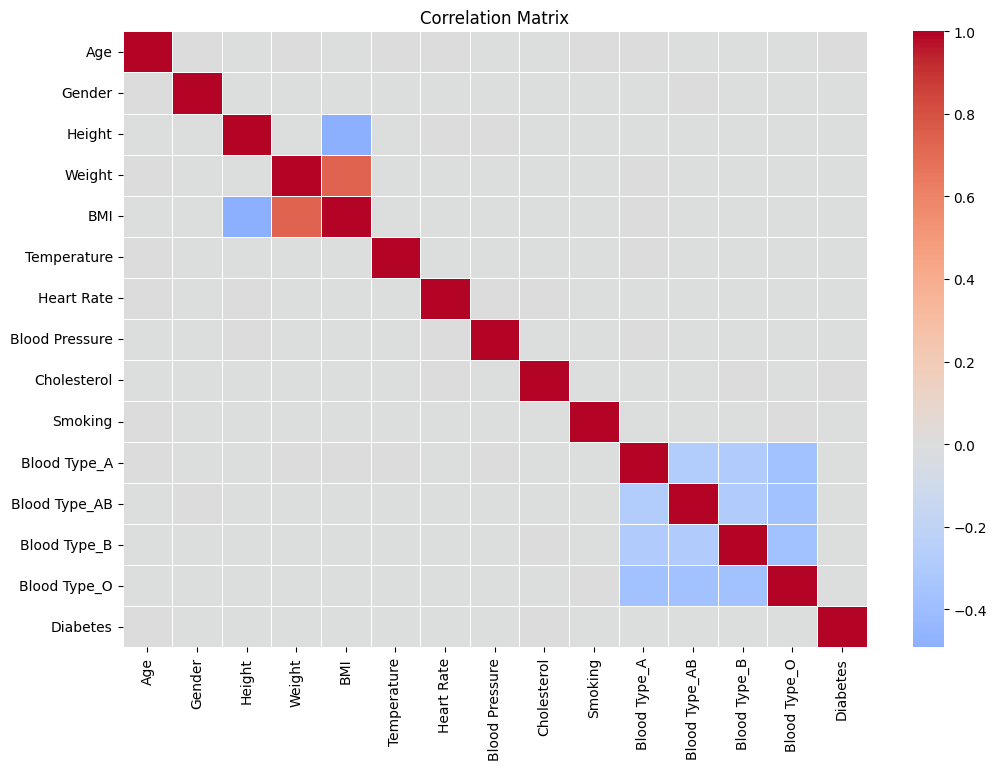

In [182]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Matrix")
plt.show()

Red-> Positive Correlation <br>
Blue-> Negative Correlation

Selecting the top 10 columns that have the highest correlation with the target variable.

In [183]:
top_10_column = correlations.abs().sort_values(ascending=False).head(10)
top_10_column

Height           0.006175
Temperature      0.006135
Age              0.003683
Cholesterol      0.003193
Gender           0.002658
Weight           0.002059
Blood Type_B     0.001973
Heart Rate       0.001873
BMI              0.001525
Blood Type_AB    0.001361
dtype: float64

**1D scatter plot**

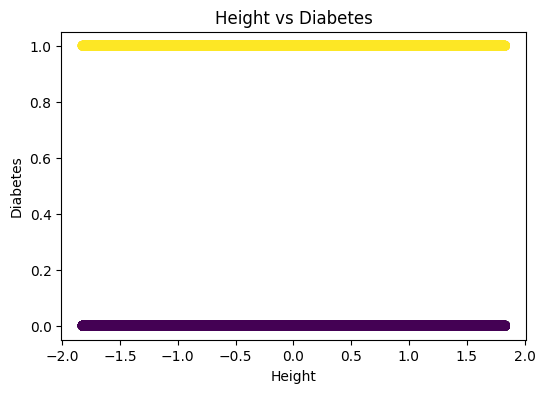

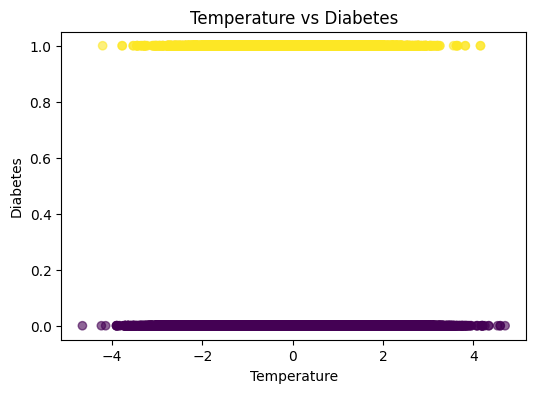

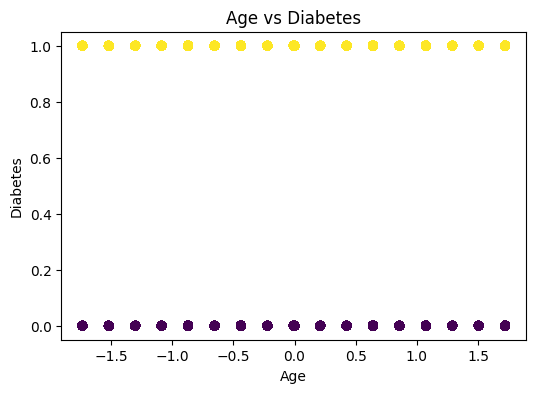

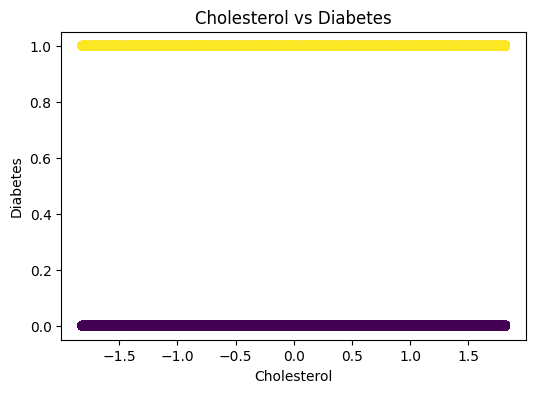

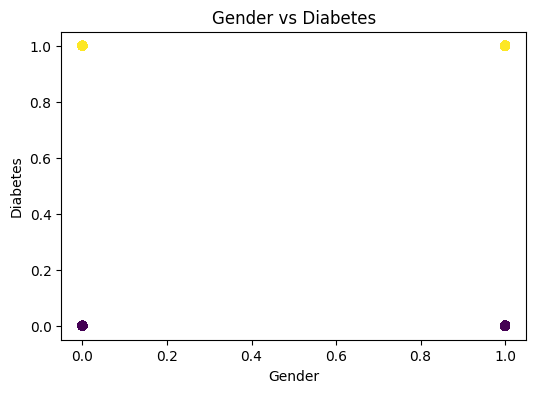

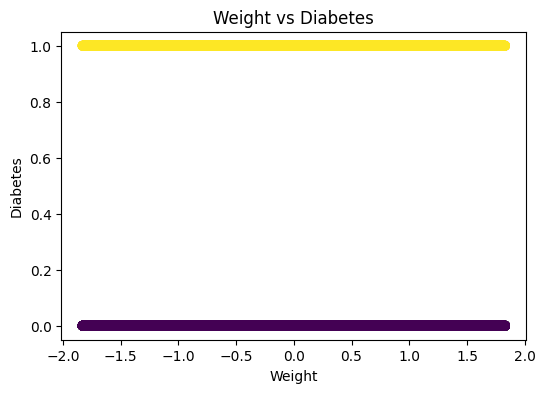

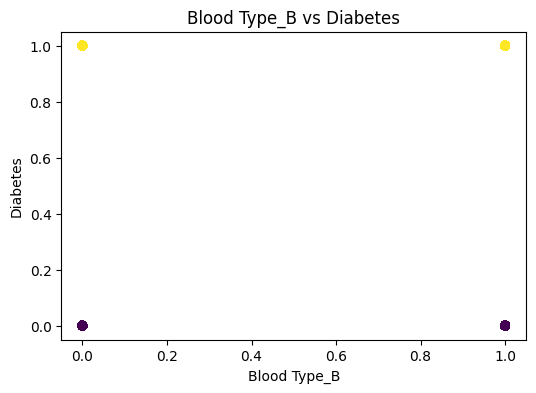

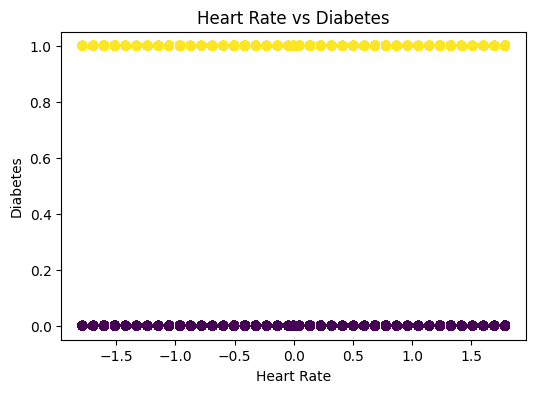

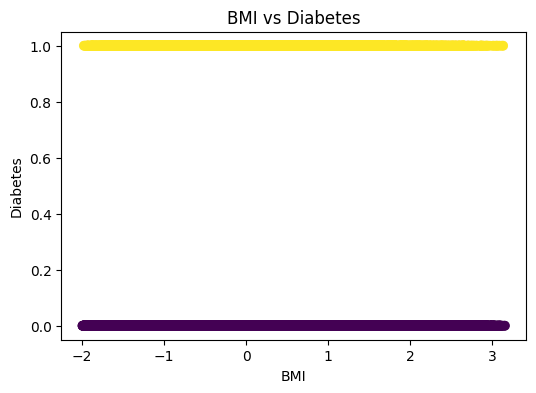

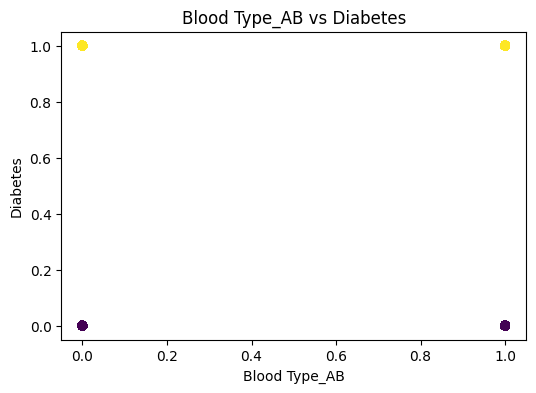

In [184]:
top_10_features = top_10_column.index
for feature in top_10_features:
    plt.figure(figsize=(6, 4))
    plt.scatter(
        features_df[feature],
        target_series,
        c=target_series,
        alpha=0.6
    )
    plt.xlabel(feature)
    plt.ylabel("Diabetes")
    plt.title(f"{feature} vs Diabetes")
    plt.show()

### 3.7 Validating the pipeline
1. At this stage, you should have a cleaned “Features” dataset containing the selected 10 features, along with the corresponding target column.
2.  You may now refer to the GitHub repository to review an example of training a simple feed-forward neural network (FNN) for a classification task using PyTorch. As part of this assignment, you are expected to design and evaluate at least “three to four” different neural network architectures, each containing a minimum of “two to three” hidden layers. It should be runnable on CPU, do not make the architectures too large.
3. Since the dataset is imbalanced, you must perform a stratified split to create the training, validation, and test sets using a 70:15:15 ratio. During training, save the model that achieves the lowest validation loss. You may use binary cross entropy loss as the loss function during training and validation. You may use Python libraries for data split.
4. For the final selected model, evaluate its performance on the test set and report the following metrics: accuracy, precision, F1-score and AUROC (with plot). You may use Python libraries for calculating metrics.

In [185]:
selected_features = top_10_column.index.tolist()
target_column = "Diabetes"
Features = full_df[selected_features + [target_column]]

In [186]:
Features.head(5)
full_df.shape

(169625, 15)

In [187]:
X = Features.drop(columns=[target_column])
y = Features[target_column]

In [188]:
print(X.shape)
print(y.shape)
print(X.columns)

(169625, 10)
(169625,)
Index(['Height', 'Temperature', 'Age', 'Cholesterol', 'Gender', 'Weight',
       'Blood Type_B', 'Heart Rate', 'BMI', 'Blood Type_AB'],
      dtype='object')


3.7.3 Splitting the dataset to create the training, validation, and test sets using a 70:15:15 ratio using Python libraries for data split.

In [189]:
from sklearn.model_selection import train_test_split

In [190]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

Designing the model.

Converting splits to Pytorch.

In [191]:
import torch
torch.manual_seed(42)
from torch.utils.data import Dataset, DataLoader

# Convert to tensors
X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)

X_val_t = torch.tensor(X_val.values, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)

X_test_t = torch.tensor(X_test.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)


PyTorch Dataset so that DataLoader can feed the data in batches.

In [192]:
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = MyDataset(X_train_t, y_train_t)
val_dataset = MyDataset(X_val_t, y_val_t)
test_dataset = MyDataset(X_test_t, y_test_t)


batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

3 architectures with 2–3 hidden layers.

In [193]:
import torch.nn as nn
class FNN1(nn.Module):  # 2 hidden layers
    def __init__(self, input_size, hidden1, hidden2, num_classes):
        super(FNN1, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, num_classes)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        return out

class FNN2(nn.Module):  # 3 hidden layers
    def __init__(self, input_size, hidden1, hidden2, hidden3, num_classes):
        super(FNN2, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, hidden3)
        self.fc4 = nn.Linear(hidden3, num_classes)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.relu(self.fc3(out))
        out = self.fc4(out)
        return out

class FNN3(nn.Module):  # 2 hidden layers with different sizes
    def __init__(self, input_size, hidden1, hidden2, num_classes):
        super(FNN3, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, num_classes)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        return out


Generic training function to reuse for all architectures.

In [194]:
def train_model(model, train_loader, val_loader, num_epochs=20, lr=0.001):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    # -------- TRAINING --------
    for epoch in range(num_epochs):
        model.train()
        running_train_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).long()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * X_batch.size(0)
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)

    # -------- FINAL VALIDATION (ONLY ONCE) --------
    model.eval()
    running_val_loss = 0
    with torch.no_grad():
        correct = 0
        total = 0
        for X_val, y_val in val_loader:
            X_val = X_val.to(device)
            y_val = y_val.to(device).long()
            outputs = model(X_val)
            _, predicted = torch.max(outputs, 1)
            total += y_val.size(0)
            correct += (predicted == y_val).sum().item()
            loss = criterion(outputs, y_val)
            running_val_loss += loss.item() * X_val.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    acc = 100 * correct / total
    #print(f"Final Validation Accuracy: {acc:.2f}%")

    return acc, epoch_train_loss, epoch_val_loss

Running the models...

In [195]:
input_size = X_train.shape[1]
num_classes = len(y_train_t.unique())

model_names = []
all_train_losses = []
all_val_losses = []

models = {
    "FNN-2-layer": FNN1(input_size, 128, 64, num_classes),
    "FNN-3-layer": FNN2(input_size, 256, 128, 64, num_classes),
    "FNN-wide":   FNN3(input_size, 200, 100, num_classes)
}

best_model = None
#best_val_acc = 0
least_val_loss = 1

for name, model in models.items():
    print(f"\nTraining {name}...")
    val_acc, train_loss, val_loss = train_model(model, train_loader, val_loader)
    
    # Store for plotting later
    model_names.append(name)
    all_train_losses.append(train_loss)  # final epoch train loss
    all_val_losses.append(val_loss)      # final epoch val loss

    #val_acc = 100 * (1 - val_losses[-1])  
    print(f"{name} Validation Accuracy: {val_acc:.4f}%")
    print(f"{name} Validation Loss: {val_loss:.4f}%")
    print(f"{name} Train Loss: {train_loss:.4f}%")

    '''if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model'''
    
    if val_loss < least_val_loss:
        least_val_loss = val_loss
        best_model = model
        best_model_name = name



Training FNN-2-layer...
FNN-2-layer Validation Accuracy: 89.9859%
FNN-2-layer Validation Loss: 0.3256%
FNN-2-layer Train Loss: 0.3232%

Training FNN-3-layer...
FNN-3-layer Validation Accuracy: 89.9859%
FNN-3-layer Validation Loss: 0.3257%
FNN-3-layer Train Loss: 0.3228%

Training FNN-wide...
FNN-wide Validation Accuracy: 89.9819%
FNN-wide Validation Loss: 0.3265%
FNN-wide Train Loss: 0.3230%


In [196]:
print("Selected Model: {}".format(best_model_name))

Selected Model: FNN-2-layer


For the final selected model, evaluating its performance on the test set and report the following metrics: accuracy, precision, F1-score and AUROC (with plot).

In [197]:
from sklearn.metrics import accuracy_score, precision_score, f1_score, roc_auc_score, roc_curve

In [198]:
def get_test_outputs(model, test_loader):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():
        for X, y in test_loader:
            X = X.to(device)
            y = y.to(device)

            outputs = model(X)

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_prob.extend(probs.cpu().numpy())

    return np.array(y_true), np.array(y_pred), np.array(y_prob)


In [199]:
y_true, y_pred, y_prob = get_test_outputs(best_model, test_loader)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
auroc = roc_auc_score(y_true, y_prob[:, 1])


In [200]:
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUROC     : {auroc:.4f}")

Accuracy  : 0.8999
Precision : 0.4499
F1-score  : 0.4736
AUROC     : 0.5216


Plotting AUROC curve.

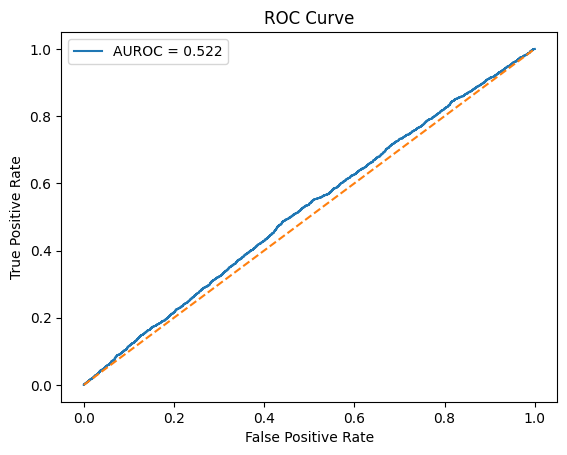

In [201]:
fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])

plt.figure()
plt.plot(fpr, tpr, label=f"AUROC = {auroc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


Printing the confusion matrix.

In [202]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
'''tp = cm[0][0]
print("TP:", tp)
print(cm[0][0])'''
print(cm)

[[22896     0]
 [ 2548     0]]


In [203]:
num_ones = target_df['Diabetes'].sum()
total_row = target_df.size
print("Number of 1 in target column: ", num_ones)
print("Number of 0 in target column: ", total_row - num_ones)

Number of 1 in target column:  16985
Number of 0 in target column:  152640


Plotting training and validation loss for report.

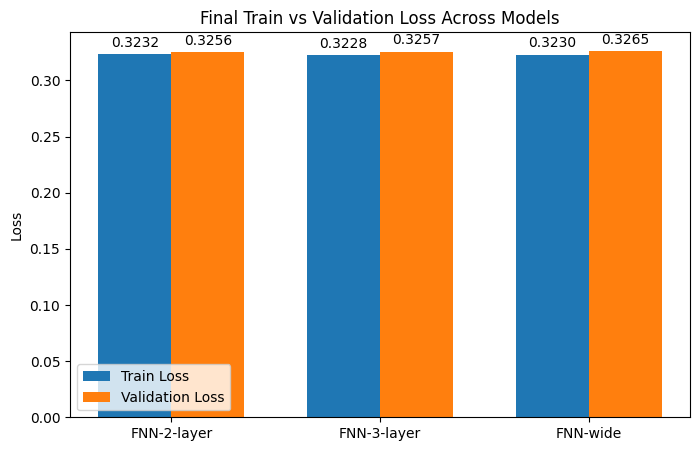

In [204]:
x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width/2, all_train_losses, width, label='Train Loss')
rects2 = ax.bar(x + width/2, all_val_losses, width, label='Validation Loss')

ax.set_ylabel('Loss')
ax.set_title('Final Train vs Validation Loss Across Models')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add labels on top of bars
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.show()
